# 6. The parametric model

`lazuli_exo.simulate(params)` builds a spectrum for *any* transiting planet. The
atmosphere comes from one POSEIDON-derived grid of the photospheric
log-pressure,

$$\zeta(\lambda) = -\ln \frac{P_{\tau=1}(\lambda)}{1\,\mathrm{bar}},$$

tabulated for two fiducial planets (1 R$_J$ at g = 10 m s$^{-2}$; 0.3 R$_J$ at g = 30 m s$^{-2}$) on a
(T, [M/H], C/O) grid. For another planet the runtime shifts $\zeta$ onto its
pressure scale along the slant-column axis $x = \tfrac12\ln[(R_p H)/(R_p H)_0]$,
applies a gray deck and a power-law haze analytically per wavelength, and maps to
depth with the exact isothermal hydrostatic relation
$R(\lambda) = R_p / (1 - (H/R_p)(\zeta - \tilde\zeta))$, so $R_p$ is the
band-median transit radius. The star is a PHOENIX mini-grid; slicersim computes
the noise live. This notebook shows the grid and validates the reconstruction
against the 14 committed POSEIDON planets.

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

try:
    plt.style.use("gks")
except OSError:
    pass

import lazuli_exo
from lazuli_exo import tables, presets, binning
from lazuli_exo.atmosphere import transmission_depth, grid_wavelengths

FIGS = Path("figs"); FIGS.mkdir(exist_ok=True)
g = tables.load_zeta_grid()
print("zeta grid:", g["zeta"].shape, g["zeta"].dtype, "| T", g["T_K"].min(), "-", g["T_K"].max(), "K;",
      "log_met", g["log_met"].min(), "-", g["log_met"].max(), "; C/O", list(g["c_to_o"]))
for f in g["meta"]["fiducials"]:
    print(f"fiducial: R_p = {f['R_p_m']/7.1492e7:.2f} RJ, g = {f['g_ms2']} m/s2, x = {f['x_column']:+.3f}")
print("POSEIDON", g["meta"]["poseidon_version"], "created", g["meta"]["created"],
      "| file", round((tables.resolve_tables_dir(None) / tables.ZETA_GRID).stat().st_size / 1e6, 1), "MB")

zeta grid: (16, 9, 4, 2, 16650) float16 | T 300.0 - 3000.0 K; log_met -1.0 - 3.0 ; C/O [np.float64(0.3), np.float64(0.55), np.float64(0.8), np.float64(1.0)]
fiducial: R_p = 1.00 RJ, g = 10.0 m/s2, x = +0.000
fiducial: R_p = 0.30 RJ, g = 30.0 m/s2, x = -1.151
POSEIDON 1.4.0 created 2026-10-04 | file 25.3 MB


## The opacity shape, $\zeta(\lambda)$

Higher $\zeta$ means the atmosphere becomes opaque higher up (lower pressure). Water bands and the alkali lines stand out; the Rayleigh slope rises to the blue. Shown binned to R = 300 for legibility (the grid itself is R = 10,000).

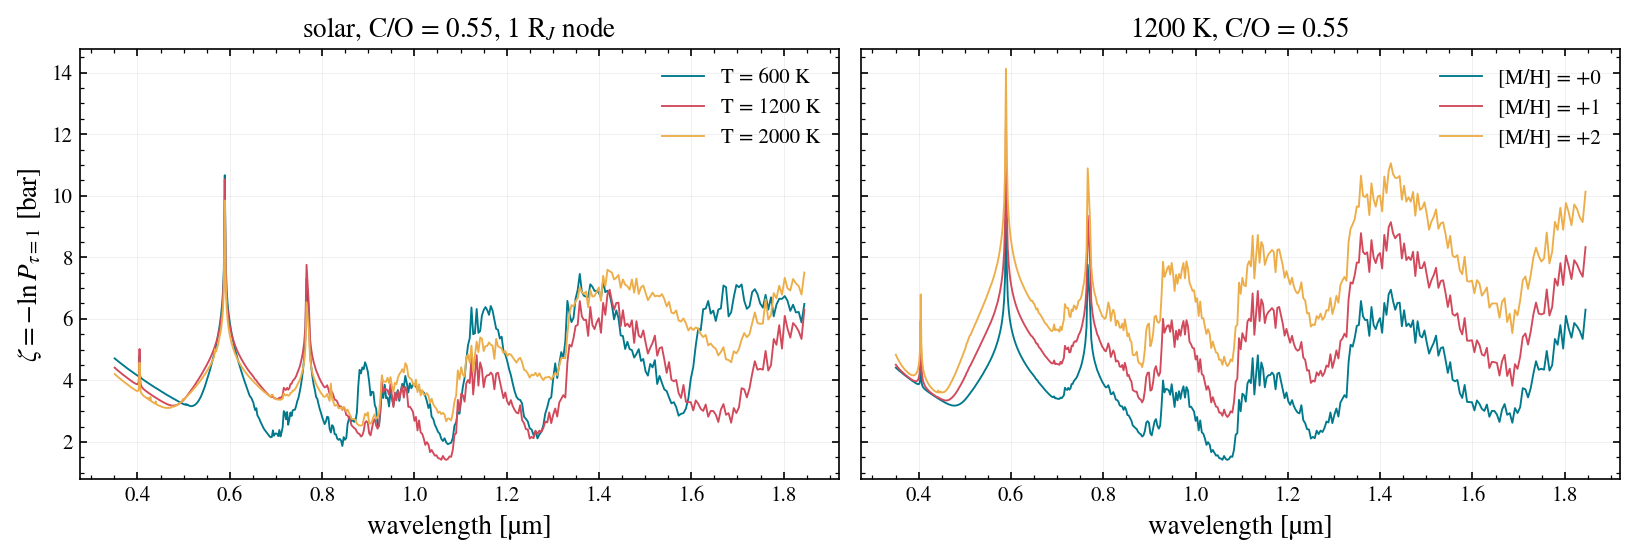

In [2]:
wl = g["wavelength_um"]
edges300 = binning.constant_R_edges(0.35, 1.849, 300); wc300 = binning.bin_centers(edges300)
def b300(z): return binning.bin_model(wl, z.astype(float), edges300)
iT = {T: int(np.argmin(abs(g["T_K"] - T))) for T in (600, 1200, 2000)}
im0 = int(np.argmin(abs(g["log_met"] - 0.0))); ico = int(np.argmin(abs(g["c_to_o"] - 0.55)))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for T, i in iT.items():
    ax[0].plot(wc300, b300(g["zeta"][i, im0, ico, 0]), lw=0.9, label=f"T = {g['T_K'][i]:.0f} K")
for met in (0.0, 1.0, 2.0):
    im = int(np.argmin(abs(g["log_met"] - met)))
    ax[1].plot(wc300, b300(g["zeta"][iT[1200], im, ico, 0]), lw=0.9, label=f"[M/H] = {met:+.0f}")
for a in ax:
    a.set_xlabel("wavelength [µm]"); a.legend(frameon=False)
ax[0].set_ylabel(r"$\zeta = -\ln P_{\tau=1}$ [bar]"); ax[0].set_title("solar, C/O = 0.55, 1 R$_J$ node")
ax[1].set_title("1200 K, C/O = 0.55")
fig.tight_layout(); fig.savefig(FIGS / "06_zeta_grid.png", dpi=150)

## Mean molecular weight from chemistry

`mu=None` takes the equilibrium-chemistry value stored with the grid. It rises steeply above 100x solar, which is what shrinks the scale height of a high-metallicity atmosphere.

{-1.0: 2.31, -0.5: 2.31, 0.0: 2.32, 0.5: 2.36, 1.0: 2.47, 1.5: 2.82, 2.0: 3.84, 2.5: 6.28, 3.0: 10.64}


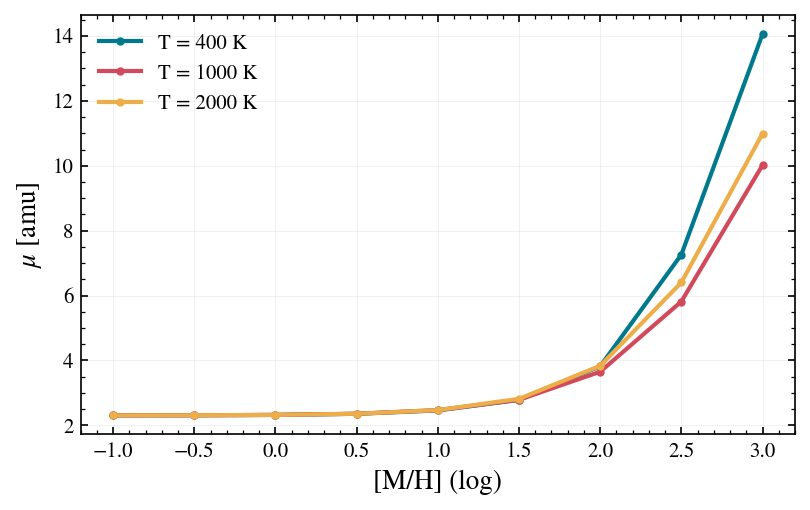

In [3]:
fig, ax = plt.subplots(figsize=(5.5, 3.5))
for T in (400, 1000, 2000):
    i = int(np.argmin(abs(g["T_K"] - T)))
    ax.plot(g["log_met"], g["mu"][i, :, ico], "o-", ms=3, label=f"T = {g['T_K'][i]:.0f} K")
ax.set_xlabel("[M/H] (log)"); ax.set_ylabel(r"$\mu$ [amu]"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIGS / "06_mu.png", dpi=150)
print({float(m): round(float(g["mu"][iT[1200], k, ico]), 2) for k, m in enumerate(g["log_met"])})

## Reconstruction vs. the POSEIDON tables: WASP-39 b

The committed table and the parametric reconstruction from the registry values, binned to R = 100. Two conventions differ and are handled here as in the validation script: the tables put the archive radius at 10 bar, so the model is given each table's own band-median radius; and POSEIDON realizes a nominal 1 mbar deck at 1.376 mbar on its 100-layer grid.

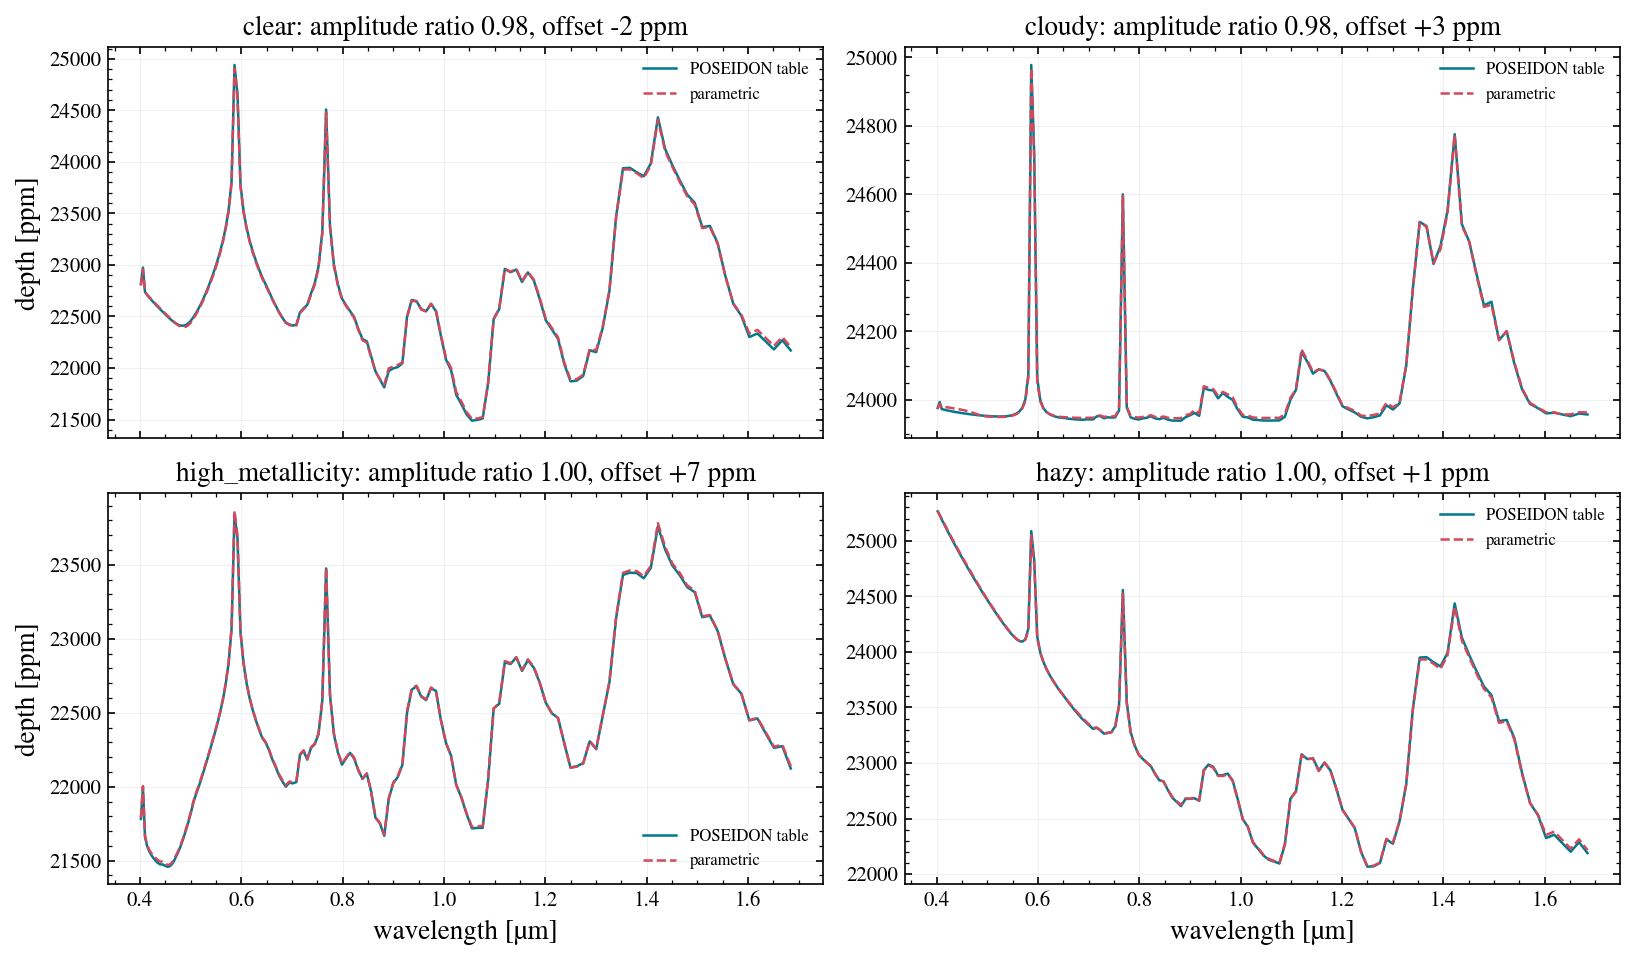

In [4]:
import sys; sys.path.insert(0, str(Path("..") / "precompute"))
from validate_zeta_grid import DECK_REALIZED_LOG_OFFSET, R_J_M, R_SUN_M
tdir = tables.resolve_tables_dir(None)
edges = binning.constant_R_edges(0.40, 1.70, 100); wc = binning.bin_centers(edges)
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), sharex=True)
for ax, scen in zip(axes.ravel(), ["clear", "cloudy", "high_metallicity", "hazy"]):
    wl_t, d_t, _ = tables.load_model(Path("..") / "precompute" / "tables", "WASP-39 b", scen)
    p = presets.showcase("WASP-39 b", scen)
    kw = {k: p[k] for k in ('T_eq_K', 'R_p_RJ', 'M_p_MJ', 'R_s_RSun', 'log_met', 'c_to_o', 'mu', 'log_P_cloud_bar', 'log_a_haze', 'haze_slope')}
    band = (wl_t >= 0.4) & (wl_t <= 1.7)
    kw["R_p_RJ"] = float(np.sqrt(np.median(d_t[band])) * p["R_s_RSun"] * R_SUN_M / R_J_M)
    if kw["log_P_cloud_bar"] is not None:
        kw["log_P_cloud_bar"] += DECK_REALIZED_LOG_OFFSET
    d_m, info = transmission_depth(wl_t, **kw)
    bt = binning.bin_model(wl_t, d_t, edges); bm = binning.bin_model(wl_t, d_m, edges)
    ax.plot(wc, bt * 1e6, lw=1.2, label="POSEIDON table")
    ax.plot(wc, bm * 1e6, lw=1.2, ls="--", label="parametric")
    ax.set_title(f"{scen}: amplitude ratio {np.ptp(bm)/np.ptp(bt):.2f}, offset {np.mean(bm-bt)*1e6:+.0f} ppm")
    ax.legend(frameon=False, fontsize=8)
for ax in axes[1]: ax.set_xlabel("wavelength [µm]")
for ax in axes[:, 0]: ax.set_ylabel("depth [ppm]")
fig.tight_layout(); fig.savefig(FIGS / "06_wasp39_validation.png", dpi=150)

## Validation table (all 14 planets)

Produced by `precompute/validate_zeta_grid.py` (issue #22 gate). Each model-vs-table comparison is made at R = 100 after removing a constant offset, against the single-transit per-bin sigma, and must pass three gates: G2, the worst binned residual is below one sigma; G5, the residual spectrum's own template S/N (how much structure the error has) is below 3; G3, the model's template S/N is within 10 % of the table's. `flat` is gated on its absolute amplitude instead. For the three planets whose POSEIDON tables were computed with the isotherm clamped to 300 K, the like-for-like row (T_eq = 300 K in the parametric model too) is the gated one. Expected failures are waivers in the script, each naming the gate and the issue that removes it (#35).

      planet         scenario  T_eq_used_K  like_for_like  gated  H_over_Rp  amp_table_ppm  amp_model_ppm  amp_ratio  rms_ppm  worst_sig  err_snr  snr_ratio       failed  waived
   GJ 1214 b            clear      567.000          False   True     0.0111         1797.0         1726.0       0.96     81.0       0.92      4.0      0.961         [G5]    True
   GJ 1214 b high_metallicity      567.000          False   True     0.0067         1632.0         1533.0       0.94     56.0       0.28      3.6      0.919         [G5]    True
   GJ 1214 b           cloudy      567.000          False   True     0.0116          321.0          270.0       0.84      6.0      -0.05      0.2      0.978           []   False
   GJ 1214 b             hazy      567.000          False   True     0.0113         2063.0         2059.0       1.00     18.0      -0.08      1.2      0.975           []   False
   GJ 1214 b             flat      567.000          False   True     0.0105            0.0            0.0     

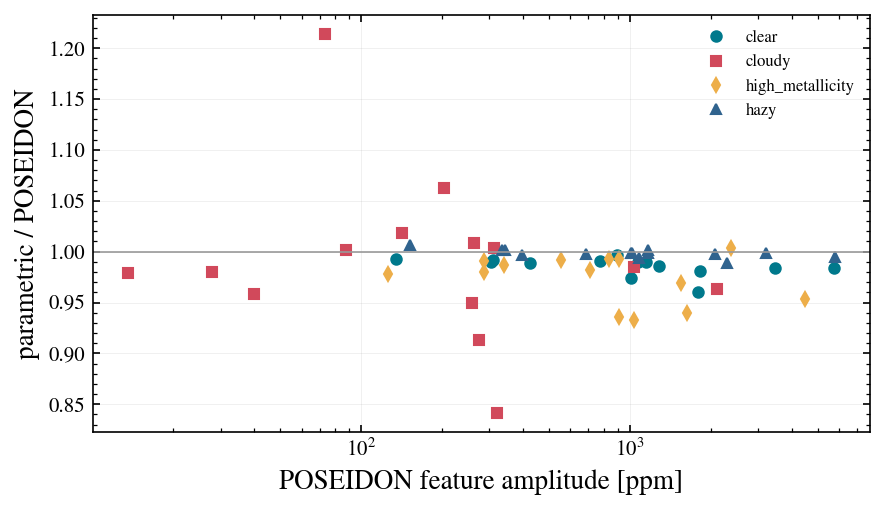

In [5]:
import pandas as pd
rows = json.loads(Path("figs/06_validation.json").read_text())["models"]
df = pd.DataFrame(rows)[["planet", "scenario", "T_eq_used_K", "like_for_like", "gated", "H_over_Rp",
                         "amp_table_ppm", "amp_model_ppm", "amp_ratio", "rms_ppm", "worst_sig", "err_snr", "snr_ratio", "failed", "waived"]]
df["waived"] = df["waived"].notna()
pd.set_option("display.max_rows", 100); pd.set_option("display.width", 200)
print(df.round({"H_over_Rp": 4, "amp_table_ppm": 0, "amp_model_ppm": 0, "amp_ratio": 2, "rms_ppm": 0, "worst_sig": 2, "err_snr": 1, "snr_ratio": 3}).to_string(index=False))
gated = df[df.gated]
passed = gated.failed.str.len() == 0
print(f"\n{int(passed.sum())}/{len(gated)} gated comparisons pass all gates; "
      f"waived: {gated[~passed & gated.waived][['planet', 'scenario']].values.tolist()}")
for r in rows:
    if r["gated"] and r["waived"] and r["failed"]:
        print("WAIVED", r["planet"], r["scenario"], r["failed"], "->", r["waived"])
assert all(not r["unwaived"] for r in rows if r["gated"]), "validation gate failed"
fig, ax = plt.subplots(figsize=(6, 3.5))
for scen, m in zip(["clear", "cloudy", "high_metallicity", "hazy"], "osd^"):
    s = gated[gated.scenario == scen]
    ax.plot(s.amp_table_ppm, s.amp_ratio, m, ms=5, label=scen)
ax.axhline(1, color="0.6", lw=0.8); ax.set_xscale("log")
ax.set_xlabel("POSEIDON feature amplitude [ppm]"); ax.set_ylabel("parametric / POSEIDON")
ax.legend(frameon=False, fontsize=8); fig.tight_layout(); fig.savefig(FIGS / "06_validation_ratios.png", dpi=150)

## A custom planet end to end

TOI-270 d with a heavier atmosphere (μ = 5), a cloud deck at 10 mbar, 20 transits. `simulate` needs slicersim and sncosmo at call time; the noise comes out of a live slicersim run on the PHOENIX SED, with the archive J (Vega) converted to AB.

g = 9.9 m/s2, H = 64 km, H/Rp = 0.0049, mu = 5.0 (user), T_clamped = False
J = 9.099 Vega -> 10.00 AB (offset 0.899); nmd [2, 2, 0], saturated px 0, slicersim 1.3.4
feature amplitude 195 ppm, median error 16 ppm
{'template_snr_diagonal': 5.596534132052765, 'band_snr': {'Na': 0.36388598240478454, 'K': 0.7947699031560366, 'H2O': 4.416474956416279, 'CH4': 2.3193116746856535, 'CO2': 1.2551630076562657}}


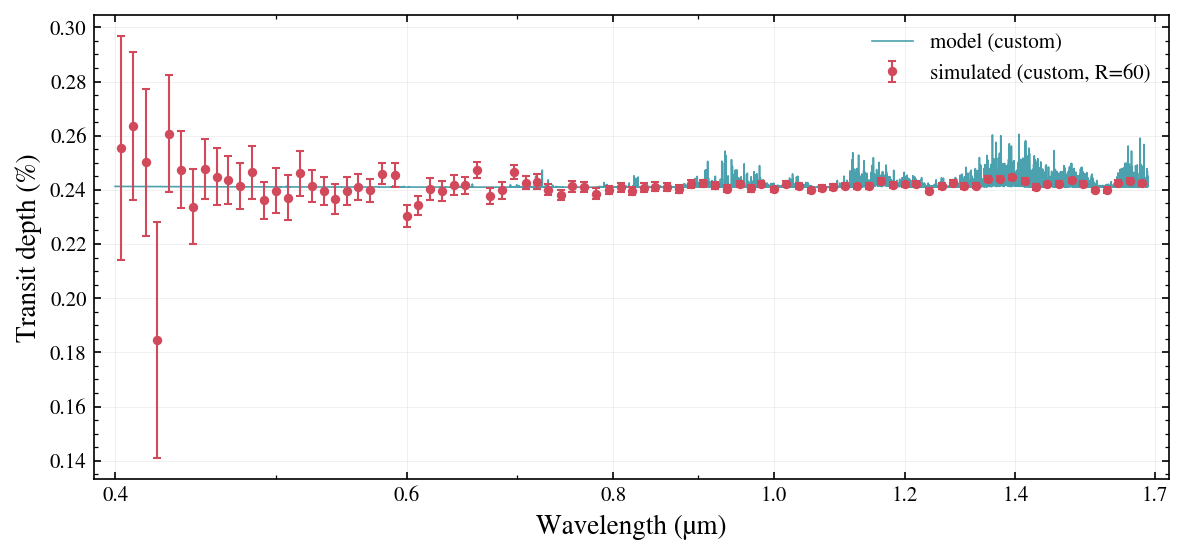

In [6]:
p = presets.showcase("TOI-270 d", "clear")
p.update(name="TOI-270 d (custom)", scenario="custom", mu=5.0, log_P_cloud_bar=-2.0)
obs = lazuli_exo.simulate(p, R=60, n_transits=20)
a, n = obs.meta["atmosphere"], obs.meta["noise"]
print(f"g = {a['g_ms2']:.1f} m/s2, H = {a['H_m']/1e3:.0f} km, H/Rp = {a['H_over_Rp']:.4f}, "
      f"mu = {a['mu_used']} ({a['mu_source']}), T_clamped = {a['T_clamped']}")
print(f"J = {n['mag_input']} Vega -> {n['mag_ab']:.2f} AB (offset {n['vega_ab_offset']:.3f}); "
      f"nmd {n['nmd_used']}, saturated px {n['nsaturated_detpx']}, slicersim {n['slicersim_version']}")
print("feature amplitude %.0f ppm, median error %.0f ppm" % (a["feature_amplitude_ppm"], np.median(obs.depth_err) * 1e6))
print(obs.detect())
fig, ax = plt.subplots(figsize=(8, 3.8))
obs.plot(ax=ax, seed=1)
fig.tight_layout(); fig.savefig(FIGS / "06_custom_toi270d.png", dpi=150)

## Summary

- One ζ grid (16 × 9 × 4 × 2 nodes at R = 10,000, ≈25 MB) plus analytic column, scale-height, deck and haze terms reproduces the per-planet POSEIDON tables to within the stated tolerances.
- `R_p` is the band-median transit radius; the tables' 10 bar reference-pressure convention only shows up as a constant offset.
- Noise is live slicersim with the Vega→AB conversion applied and reported.